# Random Forest

Many decision trees (notebook 03), each trained on a random sample of the rows and choosing each split from a random subset of features. The forest predicts by majority vote, which smooths out the mistakes of individual trees.

Two versions in `src/dosdetect/models.py`:

- `random_forest()`: 300 trees, default settings, plus an out-of-bag (OOB) accuracy estimate from the rows each tree skipped.
- `random_forest_tuned()`: tuned to catch DoS types it was never trained on. It does better on the official split's unseen types, but that advantage does not carry over to other held-out attack types (see the leave-one-attack-out section).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from dosdetect.data import prepare_all
from dosdetect.evaluate import evaluate, evaluate_all, metrics_table, plot_confusions
from dosdetect.models import MODELS

pd.set_option("display.precision", 4)

## Data

NSL-KDD and KDDCup'99, normal and DoS traffic only (`dosdetect.data.prepare_all`). Six setups, each split at 8 or 41 features:

- **official**: NSL-KDD, train on `KDDTrain+`, test on `KDDTest+`. About 23% of the test DoS rows are attack types never seen in training (apache2, mailbomb, processtable, udpstorm).
- **holdout**: NSL-KDD, stratified 80/20 split of `KDDTrain+`, so every test attack type was also seen in training.
- **kddcup**: stratified 80/20 split of the KDDCup'99 10% file (its labelled test file is no longer downloadable, so there is no official split). Like holdout, there are no unseen attack types.
- **8 features** (top 8 by |Spearman correlation| with the label, our reading of the paper's filter) or **all 41**. On the official split these are not the paper's 8: it names `dst_bytes` and `protocol_type` among its features, and neither is in our top 8 there (see the feature-importance table below and the README).

The `recall_unseen` and feature-importance results below only exist for `official`, the one setup with unseen attack types.


In [2]:
data = prepare_all()
official = data[("official", 8)]
print("Train rows:", len(official["X_train"]), " Test rows:", len(official["X_test"]))
print("Unseen DoS rows in official test:", official["unseen"].sum())
official["prep"].correlations.head(8).rename("|Spearman correlation| with label").to_frame()

Train rows: 113270  Test rows: 17169
Unseen DoS rows in official test: 1717


,|Spearman correlation| with label
same_srv_rate,0.8433
flag,0.7974
diff_srv_rate,0.7747
serror_rate,0.7712
srv_serror_rate,0.7686
dst_host_serror_rate,0.7485
dst_host_srv_serror_rate,0.7410
count,0.7366


## Results

`recall_unseen` is the share of never-seen DoS attack types the model still catches (official split only; the other splits show NaN).


In [3]:
results = evaluate_all(MODELS["random_forest"], data)
metrics_table(results)

,accuracy,precision,recall,f1,recall_seen,recall_unseen
"official, 8 features",0.8543,0.9299,0.7187,0.8108,0.8742,0.1986
"official, 41 features",0.9012,0.9845,0.7848,0.8734,0.9949,0.0821
"holdout, 8 features",0.9734,0.9913,0.9426,0.9663,NaN,NaN
"holdout, 41 features",0.9999,1.0000,0.9998,0.9999,NaN,NaN
"kddcup, 8 features",0.9994,0.9999,0.9994,0.9996,NaN,NaN
"kddcup, 41 features",1.0000,1.0000,1.0000,1.0000,NaN,NaN


### Confusion matrices

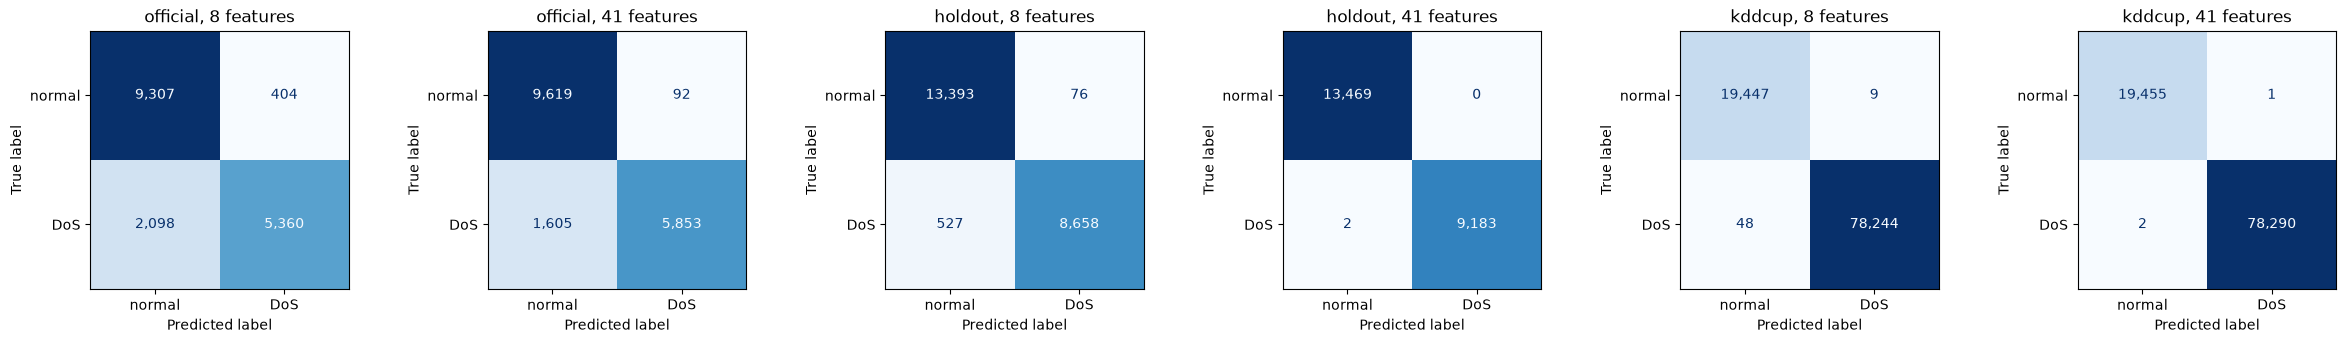

In [4]:
plot_confusions(results);

## Tuned Random Forest

`random_forest_tuned()` keeps the top 5 features by forest importance and uses shallower, regularised trees (`max_depth=10`, `min_samples_leaf=2`, `max_features=0.5`, `class_weight="balanced_subsample"`). These settings are fixed in `src/dosdetect/models.py`; they came from an earlier run of the attack-out search at the end of this notebook. The search was re-run after the feature ranking changed and picks different settings (see the end of this notebook), so the two should not be assumed to agree. The tuned model works best given all 41 features so it can choose its own. Its advantage on the official split's unseen types (`recall_unseen` above) is one test file's worth of evidence; the leave-one-attack-out section below checks it on other held-out types and finds it does not generalise.


In [5]:
tuned = evaluate_all(MODELS["random_forest_tuned"], data)
pd.concat({"default": metrics_table(results), "tuned": metrics_table(tuned)})[
    ["accuracy", "precision", "recall", "f1", "recall_unseen"]
]

accuracy  precision  recall      f1  \
default official, 8 features     0.8543     0.9299  0.7187  0.8108   
        official, 41 features    0.9012     0.9845  0.7848  0.8734   
        holdout, 8 features      0.9734     0.9913  0.9426  0.9663   
        holdout, 41 features     0.9999     1.0000  0.9998  0.9999   
        kddcup, 8 features       0.9994     0.9999  0.9994  0.9996   
        kddcup, 41 features      1.0000     1.0000  1.0000  1.0000   
tuned   official, 8 features     0.8639     0.9323  0.7405  0.8254   
        official, 41 features    0.9059     0.9893  0.7920  0.8797   
        holdout, 8 features      0.9717     0.9941  0.9357  0.9640   
        holdout, 41 features     0.9969     0.9928  0.9997  0.9962   
        kddcup, 8 features       0.9983     0.9998  0.9981  0.9990   
        kddcup, 41 features      0.9995     1.0000  0.9994  0.9997   

                               recall_unseen  
default official, 8 features          0.1986  
        official, 41 features         0.0821  
        holdout, 8 features              NaN  
        holdout, 41 features             NaN  
        kddcup, 8 features               NaN  
        kddcup, 41 features              NaN  
tuned   official, 8 features          0.2994  
        official, 41 features         0.2697  
        holdout, 8 features              NaN  
        holdout, 41 features             NaN  
        kddcup, 8 features               NaN  
        kddcup, 41 features              NaN

## Feature importance

Default forest, all 41 features, official split. Built-in importance (MDI, from training) next to permutation importance (F1 drop on the test set when one feature is shuffled). Showing the top 12 by either measure plus our top 8 by |Spearman correlation|. This cell is slower than the others because of the repeated shuffling.


,mdi,perm_f1_drop,abs_corr_with_label,in_top_8
src_bytes,0.1419,0.0788,0.7035,False
protocol_type,0.0251,0.0206,0.2666,False
flag,0.0889,0.0140,0.7974,True
dst_host_srv_rerror_rate,0.0102,0.0093,0.1296,False
dst_host_rerror_rate,0.0075,0.0077,0.1313,False
dst_bytes,0.0770,0.0076,0.7279,False
srv_rerror_rate,0.0034,0.0068,0.1796,False
logged_in,0.0082,0.0060,0.6839,False


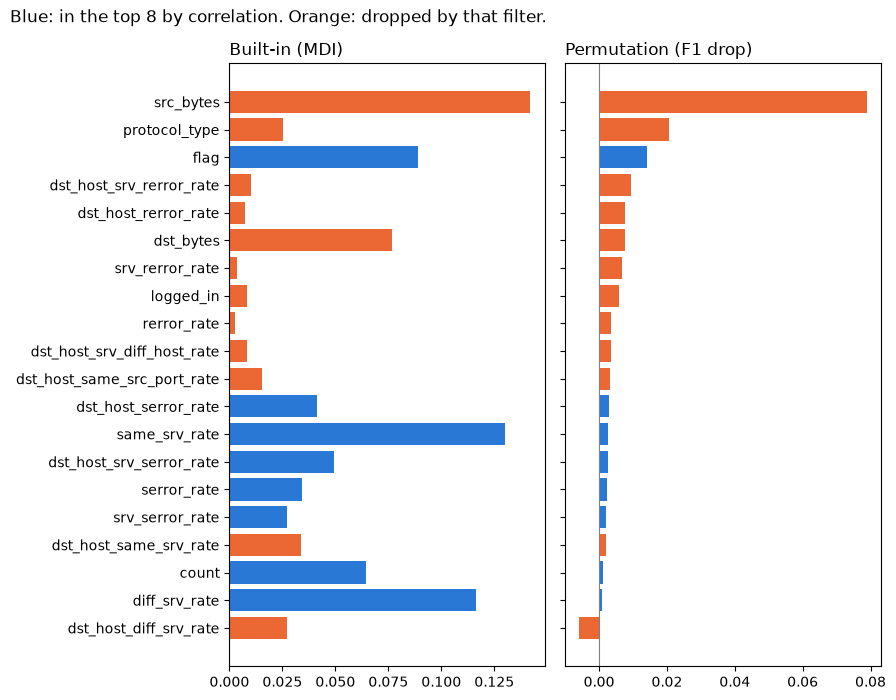

In [6]:
from sklearn.inspection import permutation_importance

full = data[("official", 41)]
forest = MODELS["random_forest"]().fit(full["X_train"], full["y_train"])
perm = permutation_importance(
    forest, full["X_test"], full["y_test"], scoring="f1", n_repeats=10, random_state=42
)

top_8 = data[("official", 8)]["prep"].selected_features
importance = pd.DataFrame(
    {
        "mdi": forest.feature_importances_,
        "perm_f1_drop": perm.importances_mean,
        "abs_corr_with_label": full["prep"].correlations.reindex(full["X_train"].columns).values,
        "in_top_8": full["X_train"].columns.isin(top_8),
    },
    index=full["X_train"].columns,
)
shown = importance[
    (importance["mdi"].rank(ascending=False) <= 12)
    | (importance["perm_f1_drop"].rank(ascending=False) <= 12)
    | importance["in_top_8"]
].sort_values("perm_f1_drop")

colors = ["#2a78d6" if kept else "#eb6834" for kept in shown["in_top_8"]]
fig, axes = plt.subplots(1, 2, figsize=(9, 0.28 * len(shown) + 1.5), sharey=True)
for ax, col, title in zip(
    axes, ["mdi", "perm_f1_drop"], ["Built-in (MDI)", "Permutation (F1 drop)"], strict=True
):
    ax.barh(shown.index, shown[col], color=colors)
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set_title(title, loc="left")
fig.suptitle(
    "Blue: in the top 8 by correlation. Orange: dropped by that filter.", x=0.01, ha="left"
)
fig.tight_layout()
importance.sort_values("perm_f1_drop", ascending=False).head(8)

### Does the correlation filter drop useful features?

`src_bytes` is clearly first on both importance measures (MDI 0.1419, permutation 0.0788), but it is not in the top 8 by |Spearman correlation| (its correlation is 0.7035, below the 8th feature's 0.7366 in the table above), so the filter drops it. `protocol_type` and `dst_bytes`, the two features the paper names, are also dropped. Retrain the default forest on a few feature sets to check. These sets were chosen *after* looking at test-set importance, so treat this as exploratory; the tuning below makes the same choice using training data only.


In [7]:
all_41 = list(full["X_train"].columns)
feature_sets = {
    "41 features": all_41,
    "41 minus src_bytes": [c for c in all_41 if c != "src_bytes"],
    "top 8": top_8,
    "top 8 + src_bytes": top_8 + ["src_bytes"],
    "top 8 + src_bytes, dst_bytes": top_8 + ["src_bytes", "dst_bytes"],
}
subset = lambda cols: {**full, "X_train": full["X_train"][cols], "X_test": full["X_test"][cols]}  # noqa: E731
metrics_table(
    {name: evaluate(MODELS["random_forest"](), subset(cols)) for name, cols in feature_sets.items()}
)[["f1", "recall_seen", "recall_unseen"]]

,f1,recall_seen,recall_unseen
41 features,0.8734,0.9949,0.0821
41 minus src_bytes,0.8629,0.9929,0.0047
top 8,0.8108,0.8742,0.1986
top 8 + src_bytes,0.9036,0.9833,0.3238
"top 8 + src_bytes, dst_bytes",0.8909,0.9890,0.2132


## How the tuned settings were chosen

Ordinary cross-validation can't tell candidates apart here: every attack type is in both training and validation, so every setting scores about 0.996-0.9998 F1. **Attack-out CV** instead hides one group of DoS types per fold (`neptune` | `smurf` | `back`+`land` | `teardrop`+`pod`) plus 1/4 of normal rows, imitating `KDDTest+`'s unseen attacks with training data only. The search also picks how many features to keep (top-k by forest importance, ranked inside each fold).

With `RUN_SEARCH = True` the next two cells redo the whole experiment (slow: far longer than any other cell here), training data only until the final scoring:

1. Two randomized searches (30 candidates each, F1, 100-tree forests): one with standard stratified 3-fold CV, one with attack-out CV.
2. Four configs (default forest on the top 8, default forest on all 41, and the best of each search) each trained with 300 trees and 5 seeds, scored on `KDDTest+`.
3. Results (mean and std over seeds, plus `cv_f1`, the best CV F1 of the search behind each tuned config) saved to `results/rf_tuning.csv`.

By default (`RUN_SEARCH = False`) it just shows the saved CSV. The search uses the official split with 41 features, so it is unaffected by the kddcup split. It is affected by the feature ranking, though: the 41 columns are ordered by correlation, and the forest's random feature choices depend on column order, so the ranking change probably explains why even the 41-feature results (and the searched settings) differ from the earlier run.


In [8]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import f1_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

from dosdetect.data import ATTACK_GROUPS, RESULTS_DIR

RUN_SEARCH = False

SEED = 42
EVAL_SEEDS = (0, 1, 2, 3, 4)
N_ITER = 30
SEARCH_SPACE = {
    "select__max_features": [5, 8, 10, 15, 20, 41],
    "rf__max_features": ["sqrt", "log2", 0.3, 0.5],
    "rf__min_samples_leaf": [1, 2, 5, 10, 20],
    "rf__max_depth": [None, 10, 20, 30],
    "rf__max_samples": [None, 0.5, 0.8],
    "rf__class_weight": [None, "balanced", "balanced_subsample"],
    "rf__criterion": ["gini", "entropy"],
}


def pipeline(seed=SEED, n_estimators=100, **params):
    """Top-k features by forest importance (k = select__max_features), then a Random Forest."""
    pipe = Pipeline(
        [
            (
                "select",
                SelectFromModel(
                    RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=seed),
                    threshold=-np.inf,  # rank only; max_features picks k
                    max_features=41,
                ),
            ),
            ("rf", RandomForestClassifier(n_estimators=n_estimators, n_jobs=-1, random_state=seed)),
        ]
    )
    return pipe.set_params(**params)


def attack_out_folds(train_df, seed=SEED):
    """Each fold validates on one held-out DoS group plus 1/4 of normal rows."""
    normal = np.flatnonzero(train_df["label"].to_numpy() == 0)
    chunks = np.array_split(np.random.default_rng(seed).permutation(normal), len(ATTACK_GROUPS))
    for attacks, chunk in zip(ATTACK_GROUPS, chunks, strict=True):
        val = np.concatenate([np.flatnonzero(train_df["attack"].isin(attacks)), chunk])
        yield np.setdiff1d(np.arange(len(train_df)), val), val


def run_search(d, cv, label):
    """Randomized search on the training data; returns (best params, best CV F1)."""
    s = RandomizedSearchCV(
        pipeline(),
        SEARCH_SPACE,
        n_iter=N_ITER,
        scoring="f1",
        cv=cv,
        random_state=SEED,
        n_jobs=1,
        refit=False,
    ).fit(d["X_train"], d["y_train"])
    scores = s.cv_results_["mean_test_score"]
    print(
        f"{label:10} best CV F1 {scores.max():.4f} (candidates {scores.min():.4f}-{scores.max():.4f})"
    )
    print(f"{'':10} {s.best_params_}")
    return s.best_params_, s.best_score_


def seed_scores(d, params):
    """Train with 300 trees for each of EVAL_SEEDS; F1 and seen/unseen DoS recall on the test set."""
    dos = d["y_test"].to_numpy() == 1
    rows = []
    for seed in EVAL_SEEDS:
        pipe = pipeline(seed=seed, n_estimators=300, **params)
        pred = pipe.fit(d["X_train"], d["y_train"]).predict(d["X_test"])
        rows.append(
            {
                "f1": f1_score(d["y_test"], pred),
                "recall_seen": pred[dos & ~d["unseen"]].mean(),
                "recall_unseen": pred[d["unseen"]].mean(),
            }
        )
    return pd.DataFrame(rows)

In [9]:
if RUN_SEARCH:
    standard, standard_f1 = run_search(
        full, StratifiedKFold(3, shuffle=True, random_state=SEED), "standard"
    )
    attack_out, attack_out_f1 = run_search(
        full, list(attack_out_folds(full["train_df"])), "attack-out"
    )

    # name: (data, params, cv_f1); "top 8" uses the 8-feature preprocessor's columns
    configs = {
        "default, top 8": (data[("official", 8)], {"select__max_features": 8}, np.nan),
        "default, 41": (full, {"select__max_features": 41}, np.nan),
        "tuned (standard CV)": (full, standard, standard_f1),
        "tuned (attack-out CV)": (full, attack_out, attack_out_f1),
    }
    rows = []
    for name, (d, params, cv_f1) in configs.items():
        res = seed_scores(d, params)
        rows.append(
            {
                "config": name,
                **res.mean().add_suffix("_mean"),
                **res.std().add_suffix("_std"),
                "cv_f1": cv_f1,
                "params": params,
            }
        )
    pd.DataFrame(rows).to_csv(RESULTS_DIR / "rf_tuning.csv", index=False, float_format="%.4f")

pd.read_csv(RESULTS_DIR / "rf_tuning.csv", index_col="config").drop(columns="params")

,f1_mean,recall_seen_mean,recall_unseen_mean,f1_std,recall_seen_std,recall_unseen_std,cv_f1
config,,,,,,,
"default, top 8",0.8111,0.8738,0.2048,0.0022,0.0006,0.0153,NaN
"default, 41",0.8720,0.9954,0.0684,0.0032,0.0004,0.0209,NaN
tuned (standard CV),0.8773,0.9972,0.0978,0.0040,0.0001,0.0274,0.9998
tuned (attack-out CV),0.8833,0.9983,0.1406,0.0053,0.0002,0.0375,0.0797


## Timing

Medians of 5 fit-and-predict runs per model and setup, on an 8-core machine with other background load, read from `results/timing.csv` (written by `python -m dosdetect.timing`; nothing is re-timed here). Both forests use all cores (`n_jobs=-1`), so these times depend on the core count. Ratios are within the same setup: prediction time against naive Bayes, training time against the decision tree.


In [10]:
timing = pd.read_csv(RESULTS_DIR / "timing.csv")
forests = timing[timing["model"].isin(["random_forest", "random_forest_tuned"])]
forests.set_index(["split", "n_features", "model"])[
    [
        "train_s_median",
        "predict_s_median",
        "train_ratio_vs_decision_tree",
        "predict_ratio_vs_naive_bayes",
    ]
].round(3)

train_s_median  predict_s_median  \
split    n_features model                                                   
official 8          random_forest                 3.215             0.169   
                    random_forest_tuned           4.178             0.206   
         41         random_forest                 4.563             0.158   
                    random_forest_tuned           4.303             0.199   
holdout  8          random_forest                 2.507             0.177   
                    random_forest_tuned           3.759             0.199   
         41         random_forest                 3.053             0.162   
                    random_forest_tuned           3.760             0.195   
kddcup   8          random_forest                 7.981             0.220   
                    random_forest_tuned           9.616             0.248   
         41         random_forest                11.213             0.219   
                    random_forest_tuned          10.600             0.256   

                                         train_ratio_vs_decision_tree  \
split    n_features model                                               
official 8          random_forest                              37.854   
                    random_forest_tuned                        49.186   
         41         random_forest                              10.677   
                    random_forest_tuned                        10.069   
holdout  8          random_forest                              53.067   
                    random_forest_tuned                        79.566   
         41         random_forest                               9.893   
                    random_forest_tuned                        12.184   
kddcup   8          random_forest                              47.053   
                    random_forest_tuned                        56.697   
         41         random_forest                              17.292   
                    random_forest_tuned                        16.346   

                                         predict_ratio_vs_naive_bayes  
split    n_features model                                              
official 8          random_forest                             142.512  
                    random_forest_tuned                       173.647  
         41         random_forest                              58.243  
                    random_forest_tuned                        73.093  
holdout  8          random_forest                             151.659  
                    random_forest_tuned                       170.622  
         41         random_forest                              48.669  
                    random_forest_tuned                        58.598  
kddcup   8          random_forest                              66.738  
                    random_forest_tuned                        75.133  
         41         random_forest                              15.875  
                    random_forest_tuned                        18.593

In [11]:
forests.groupby("model")[["train_ratio_vs_decision_tree", "predict_ratio_vs_naive_bayes"]].agg(
    ["min", "max"]
).round(1)

train_ratio_vs_decision_tree        \
                                             min   max   
model                                                    
random_forest                                9.9  53.1   
random_forest_tuned                         10.1  79.6   

                    predict_ratio_vs_naive_bayes         
                                             min    max  
model                                                    
random_forest                               15.9  151.7  
random_forest_tuned                         18.6  173.6

## Leave-one-attack-out

The official split has only one set of unseen attack types, so this checks the same question on more. `results/attack_out.csv` (from `python -m dosdetect.attack_out`; read here, not re-run) holds out one `ATTACK_GROUPS` group at a time (`neptune`, `smurf`, `back`+`land`, `teardrop`+`pod`) from `KDDTrain+` and KDDCup'99, trains on the rest, and tests on a 20% split of the seen rows plus every held-out row (at most 20,000). `recall_heldout` is the share of held-out DoS rows flagged, `recall_seen` the same for seen DoS types, `false_alarm_rate` the share of normal rows flagged. **One seed only.** Always read `recall_heldout` next to `false_alarm_rate`: a model that flags everything has perfect recall.


In [12]:
loao = pd.read_csv(RESULTS_DIR / "attack_out.csv")
loao_rf = loao[loao["model"].isin(["random_forest", "random_forest_tuned"])]
loao_rf.pivot_table(
    index=["dataset", "n_features", "group"],
    columns="model",
    values=["recall_heldout", "recall_seen", "false_alarm_rate"],
).swaplevel(axis=1).sort_index(axis=1)

model                              random_forest                             \
                                false_alarm_rate recall_heldout recall_seen   
dataset n_features group                                                      
kddcup  8          back+land              0.0011         0.0004      0.9996   
                   neptune                0.0003         0.9123      0.9998   
                   smurf                  0.0001         0.0000      0.9998   
                   teardrop+pod           0.0005         0.0386      0.9997   
        41         back+land              0.0000         0.0018      1.0000   
                   neptune                0.0000         0.0000      1.0000   
                   smurf                  0.0000         0.0000      0.9998   
                   teardrop+pod           0.0000         0.0370      1.0000   
nsl-kdd 8          back+land              0.0012         0.0154      0.9908   
                   neptune                0.0004         0.0000      0.9862   
                   smurf                  0.0006         0.0000      0.9998   
                   teardrop+pod           0.0028         0.0814      0.9614   
        41         back+land              0.0001         0.0031      0.9996   
                   neptune                0.0000         0.0000      0.9979   
                   smurf                  0.0004         0.0000      1.0000   
                   teardrop+pod           0.0004         0.0842      1.0000   

model                           random_forest_tuned                             
                                   false_alarm_rate recall_heldout recall_seen  
dataset n_features group                                                        
kddcup  8          back+land                 0.0008         0.0004      0.9985  
                   neptune                   0.0001         0.0014      0.9920  
                   smurf                     0.0003         0.0000      0.9998  
                   teardrop+pod              0.0007         0.7056      0.9992  
        41         back+land                 0.0004         0.0004      0.9998  
                   neptune                   0.0001         0.9836      0.9999  
                   smurf                     0.0010         0.0000      0.9739  
                   teardrop+pod              0.0002         0.1698      0.9998  
nsl-kdd 8          back+land                 0.0019         0.0185      0.9881  
                   neptune                   0.0025         0.0003      0.9809  
                   smurf                     0.0009         0.0000      0.9995  
                   teardrop+pod              0.0032         0.0000      0.9607  
        41         back+land                 0.0059         0.0185      0.9997  
                   neptune                   0.0001         0.0186      0.9947  
                   smurf                     0.0015         0.0000      0.9982  
                   teardrop+pod              0.0014         0.0000      0.9996

In [13]:
loao_means = loao_rf.groupby(["dataset", "n_features", "model"])[
    ["recall_heldout", "recall_seen", "false_alarm_rate"]
].mean()
loao_means.unstack("model").swaplevel(axis=1).sort_index(axis=1)

model                 random_forest                             \
                   false_alarm_rate recall_heldout recall_seen   
dataset n_features                                               
kddcup  8                    0.0005         0.2378      0.9997   
        41                   0.0000         0.0097      1.0000   
nsl-kdd 8                    0.0012         0.0242      0.9846   
        41                   0.0002         0.0218      0.9994   

model              random_forest_tuned                             
                      false_alarm_rate recall_heldout recall_seen  
dataset n_features                                                 
kddcup  8                       0.0005         0.1769      0.9974  
        41                      0.0004         0.2884      0.9933  
nsl-kdd 8                       0.0021         0.0047      0.9823  
        41                      0.0022         0.0093      0.9980

In [14]:
gap = loao_rf.pivot_table(
    index=["dataset", "n_features", "group"], columns="model", values="recall_heldout"
)
gap["tuned minus default"] = gap["random_forest_tuned"] - gap["random_forest"]
wins = gap.groupby(["dataset", "n_features"])["tuned minus default"].agg(
    groups_tuned_higher=lambda s: int((s > 0).sum()), mean_difference="mean"
)
wins

groups_tuned_higher  mean_difference
dataset n_features                                      
kddcup  8                             1          -0.0610
        41                            2           0.2787
nsl-kdd 8                             2          -0.0195
        41                            2          -0.0125

## Takeaways

Numbers below come from the output tables above and below; sources are listed under each bullet.

- **On the official file the default forest is good but not great**: 0.9012 accuracy with 41 features and 0.8543 with 8 (results table). On the NSL-KDD holdout split it is near-perfect (0.9999 accuracy at 41 features) and on the KDDCup split it is effectively perfect (1.0000 at 41, 0.9994 at 8). The official file is hard only because of the attack types missing from training.
- **The default forest is bad at new attack types**: recall on never-seen DoS types is 0.0821 (41 features) and 0.1986 (8 features) on the official split (results table); over 5 seeds, 0.0684 and 0.2048 (CSV table). It fits known attacks very tightly. Fewer features means more recall on unseen types but much lower recall on seen ones (0.8738 vs 0.9954 over 5 seeds).
- **Feature importance disagrees with the correlation filter.** The forest relies most on `src_bytes` (MDI 0.1419, permutation 0.0788), then `flag` on MDI and `protocol_type` on permutation. The top-8 filter drops `src_bytes` and `protocol_type`. Adding `src_bytes` back to the top 8 raises F1 from 0.8108 to 0.9036 and unseen-type recall from 0.1986 to 0.3238. Removing it from the 41 drops F1 only from 0.8734 to 0.8629 but unseen-type recall from 0.0821 to 0.0047 (feature-set table). Adding `dst_bytes` too gives F1 0.8909, below the 0.9036 without it.
- **Even within the training data, a forest can't catch DoS types it hasn't seen**: the best attack-out CV F1 is only 0.0797, against 0.9998 for standard CV (`cv_f1` in the CSV table). This reproduces the official split's weakness without touching test data.
- **Attack-out tuning gives a modest gain this time.** Over 5 seeds the attack-out-tuned forest (all 41 features) reaches 0.8833 F1 versus 0.8720 for the default 41 and 0.8773 for standard-CV tuning, with unseen-type recall 0.1406 versus 0.0684 (about double) and no loss of seen recall (0.9983 vs 0.9954). It still does not reach the default top-8 forest's unseen recall (0.2048), which pays for it with a much lower F1 (0.8111) and seen recall. Unseen recall also varies a lot by seed (std 0.0375 for the attack-out-tuned forest). The fixed `random_forest_tuned()` in `models.py` (5 features) scores higher unseen recall on a single seed (0.2697 at 41 features, 0.2994 at 8, versus 0.0821 and 0.1986 for the default; tuned-vs-default table) than the freshly searched settings, so the search result here is not a clear improvement over it.
- **Timing** (`timing.csv`, median of 5 runs on an 8-core machine with other background load; forests use all cores): training takes 9.9x to 53.1x the decision tree's time for the default forest and 10.1x to 79.6x for the tuned one, and prediction takes 15.9x to 151.7x naive Bayes's time (default) and 18.6x to 173.6x (tuned) (min/max table in the Timing section). For example on the official split at 41 features the default forest trains in 4.563 s and predicts in 0.158 s (first timing table). The tuned forest is slower to predict in every setup (0.195 to 0.256 s against 0.158 to 0.220 s).
- **Leave-one-attack-out confirms the default forest misses unseen attack types** (one seed). Mean `recall_heldout` is 0.0097 and 0.2378 on KDDCup'99 at 41 and 8 features, and 0.0218 and 0.0242 on NSL-KDD, while `recall_seen` stays at 0.9846 or above and false alarms at 0.0012 or below (means table). Per group it is almost always 0.0000 to 0.0842; the exceptions are `neptune` on KDDCup'99 at 8 features (0.9123), which accounts for most of that dataset's 0.2378 mean (per-group table).
- **The tuned forest's unseen-attack advantage does not generalise.** It beats the default on mean `recall_heldout` only on KDDCup'99 at 41 features (0.2884 vs 0.0097), and there the gain comes from two groups, `neptune` (0.9836 vs 0.0000) and `teardrop+pod` (0.1698 vs 0.0370), with false alarms still low (0.0004 mean vs 0.0000). It is worse on KDDCup'99 at 8 features (0.1769 vs 0.2378) and on NSL-KDD at 8 features (0.0047 vs 0.0242) and 41 features (0.0093 vs 0.0218) (means table). It scored higher on 1 of 4 groups at KDDCup'99 8 features and on 2 of 4 elsewhere, with mean differences of -0.0610, 0.2787, -0.0195 and -0.0125 (last table). It also has more false alarms on NSL-KDD (0.0021 and 0.0022 vs 0.0012 and 0.0002) and slightly lower `recall_seen` everywhere. So the official split's 0.2697 and 0.2994 versus 0.0821 and 0.1986 for the default is not evidence that the tuned settings catch more new attack types in general; the claim holds on that one file and, in this one-seed experiment, on one of four dataset and feature-count combinations.
